#**Data Visualization**
This notebook will have 3 distinct visualizations of the data using 2 subsets of data:
1. 400 random posts from 2010-2026 in a variety of 35 popular subreddits.
2. All posts in 5 popular political subreddits from April 2025 - February 2026.

**Visualizations using Subset 1:**
* Subreddit popularity from 2010-2026.
* Correlation between score and number of comments over time accross each of the 70 subreddits.

**Visualization using Subset 2:**
* What percent of posts on the top political subreddits are created by what users?
* Compare to post distribution of r/DIY (?)


In [ ]:
# imports
from datasets import load_dataset
import duckdb
import os
import time
import pandas as pd
import pyarrow.dataset as ds
import pyarrow.compute as pc
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import networkx as nx

# duckdb initialization
db_cnx = duckdb.connect()

In [ ]:
# mounting google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# defining curated subsets of data
random_general_subset = '/content/drive/MyDrive/curated-reddit-data-general/combined-reddit-data.parquet'
political_subset = '/content/drive/MyDrive/curated-reddit-data-political/combined-reddit-data-political.parquet'

In [ ]:
# defining lists of subreddits for the 2 subsets of data
subreddits_random_general = [
    # news and politics
    "politicaldiscussion", "politics", "worldnews", "conservative", "conspiracy",
    # technology and science
    "chatgpt", "askscience", "technology", "singularity", "machinelearning",
    # business and finance
    "wallstreetbets", "personalfinance", "investing", "fire", "cryptocurrency",
    # education and career
    "recruitinghell", "careerguidance", "jobs", "cscareerquestions", "antiwork",
    # discussion and support
    "askreddit", "unpopularopinion", "nostupidquestions", "amitheasshole", "offmychest",
    # media and entertainment
    "books", "popculturechat", "fauxmoi", "netflix", "television",
    # lifestyle, hobbies, and living
    "diy", "travel", "skincareaddiction", "lifeprotips", "fitness"
]

subreddits_political = ["politicaldiscussion", "politics", "worldnews", "conservative", "conspiracy"]

# dictionary for grouping the subreddits by category
category_mapping = {
    "politicaldiscussion": "News & Politics", "politics": "News & Politics", "worldnews": "News & Politics", "conservative": "News & Politics", "conspiracy": "News & Politics",
    "chatgpt": "Tech & Science", "askscience": "Tech & Science", "technology": "Tech & Science", "singularity": "Tech & Science", "machinelearning": "Tech & Science",
    "wallstreetbets": "Business & Finance", "personalfinance": "Business & Finance", "investing": "Business & Finance", "fire": "Business & Finance", "cryptocurrency": "Business & Finance",
    "recruitinghell": "Education & Career", "careerguidance": "Education & Career", "jobs": "Education & Career", "cscareerquestions": "Education & Career", "antiwork": "Education & Career",
    "askreddit": "Discussion & Support", "unpopularopinion": "Discussion & Support", "nostupidquestions": "Discussion & Support", "amitheasshole": "Discussion & Support", "offmychest": "Discussion & Support",
    "books": "Media & Entertainment", "popculturechat": "Media & Entertainment", "fauxmoi": "Media & Entertainment", "netflix": "Media & Entertainment", "television": "Media & Entertainment",
    "diy": "Lifestyle & Hobbies", "travel": "Lifestyle & Hobbies", "skincareaddiction": "Lifestyle & Hobbies", "lifeprotips": "Lifestyle & Hobbies", "fitness": "Lifestyle & Hobbies"
}

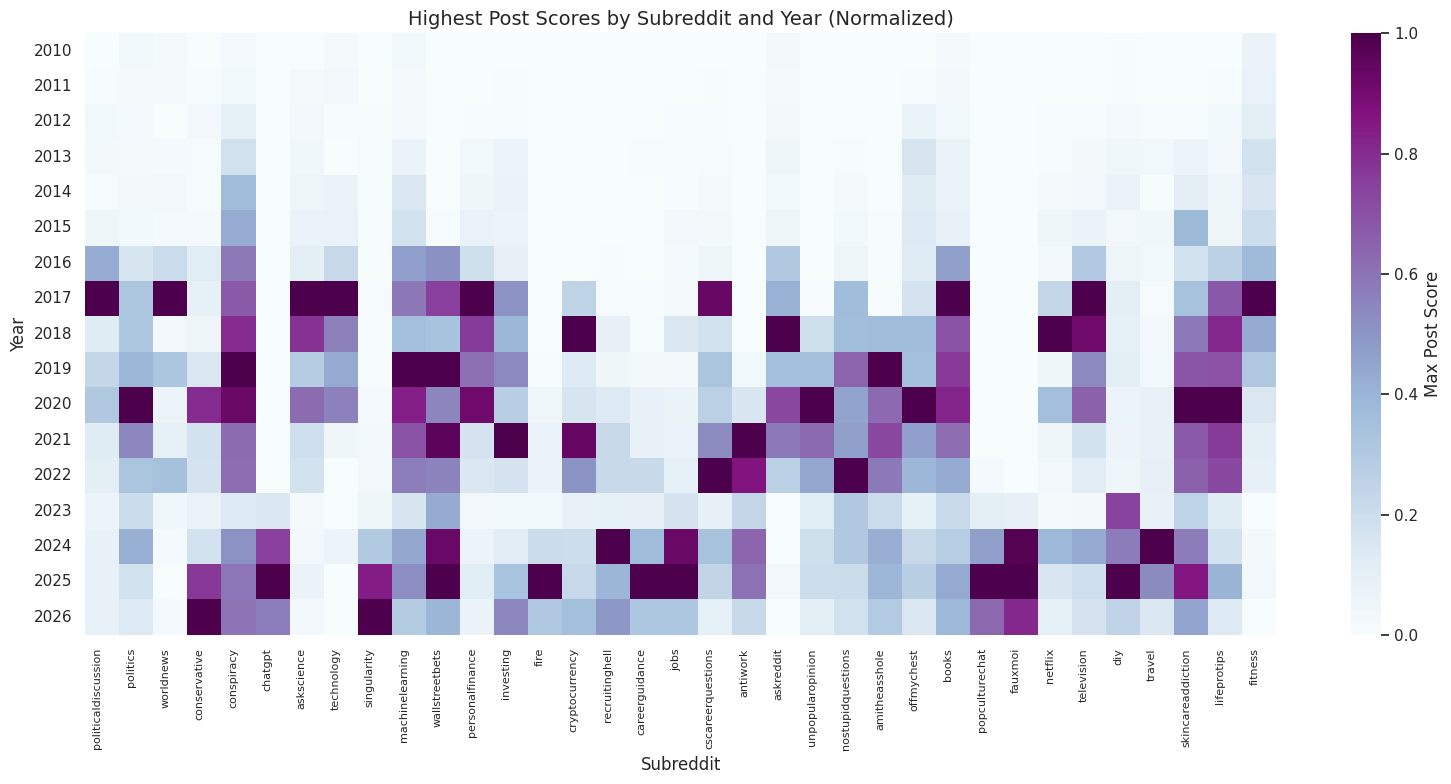

In [ ]:
# first visualization - heatmap showing subreddit popularity (highest scoring post) from 2010-2026
# get max score post (upvotes) for every subreddit for every year
query = f"""
    SELECT
        CAST(strftime(to_timestamp(created_utc), '%Y') AS INTEGER) AS post_year,
        LOWER(subreddit) AS subreddit,
        MAX(score) AS max_score
    FROM read_parquet('{random_general_subset}')
    WHERE score IS NOT NULL AND subreddit IS NOT NULL
    GROUP BY 1, 2
    ORDER BY post_year DESC, max_score DESC;
"""

# converting the duckdb query results into a pandas dataframe
subreddit_yearly_max = db_cnx.sql(query).df()

# pivoting the table so that rows = years, columns = all subreddits, values = highest score
pivot_scores = subreddit_yearly_max.pivot_table(
    index='post_year',
    columns='subreddit',
    values='max_score',
    aggfunc='max'
).fillna(0)

# reordering the columns based on the category list, so they're grouped by category
ordered_cols = [sub for sub in subreddits_random_general if sub in pivot_scores.columns]
pivot_scores = pivot_scores[ordered_cols]

# normalize each column (subreddit) to a 0-1 scale based on its own historical maximum
pivot_normalized = pivot_scores.div(pivot_scores.max(axis=0), axis=1)

# creating the heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(
    # pivot_scores,     # uncomment to view non-normalized (absolute/actual scores)
    pivot_normalized,   # normalizing by column (relative 0-1 by subreddit)
    cmap='BuPu',
    annot=False,
    fmt='.0f',
    cbar_kws={'label': 'Max Post Score'}
)

plt.title('Highest Post Scores by Subreddit and Year (Normalized)', fontsize=14)
plt.xlabel('Subreddit', fontsize=12)
plt.ylabel('Year', fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=8)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

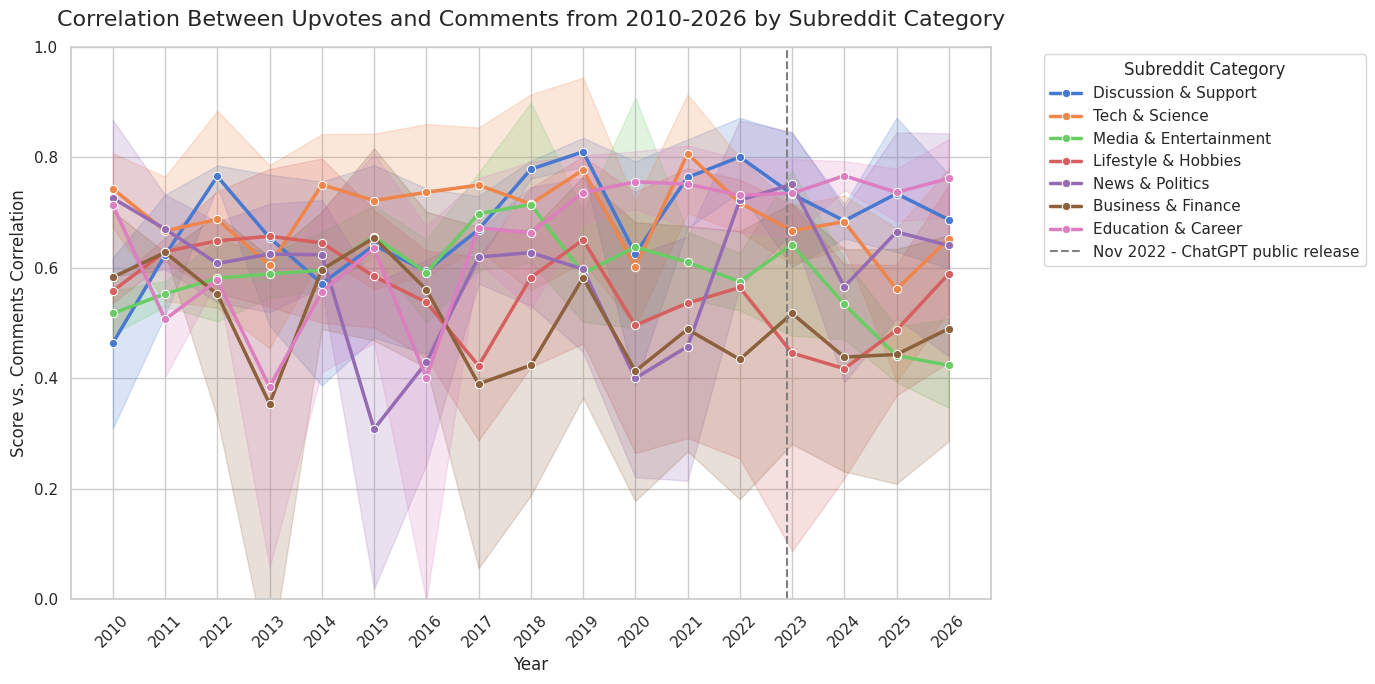

In [ ]:
# second visualization - showing the correlation between upvotes and number of comments in various subreddit categories from 2010-2026
# query and determine the correlation coefficient using duckdb built in corr() function
query = f"""
    SELECT
        CAST(strftime(to_timestamp(created_utc), '%Y') AS INTEGER) AS post_year,
        LOWER(subreddit) AS subreddit,
        corr(score, num_comments) AS engagement_correlation
    FROM read_parquet('{random_general_subset}')
    WHERE score IS NOT NULL AND num_comments IS NOT NULL
    GROUP BY 1, 2
    ORDER BY post_year ASC;
"""

upvote_comment_corr = db_cnx.sql(query).df()

# map the subreddits to their categories per the previously defined dictionary
upvote_comment_corr['category'] = upvote_comment_corr['subreddit'].map(category_mapping)

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# creating the lineplot
sns.lineplot(
    data=upvote_comment_corr,
    x='post_year',
    y='engagement_correlation',
    hue='category',
    palette='muted',
    linewidth=2.5,
    marker='o'
)

# also adding a ticked line for when chatgpt was released
plt.axvline(x=2022.9, color='gray', linestyle='--', linewidth=1.5, label='Nov 2022 - ChatGPT public release')

plt.title('Correlation Between Upvotes and Comments from 2010-2026 by Subreddit Category', fontsize=16, pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Score vs. Comments Correlation', fontsize=12)
plt.legend(title='Subreddit Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xticks(range(2010, 2027), rotation=45)
plt.ylim(0, 1.0)

plt.tight_layout()
plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

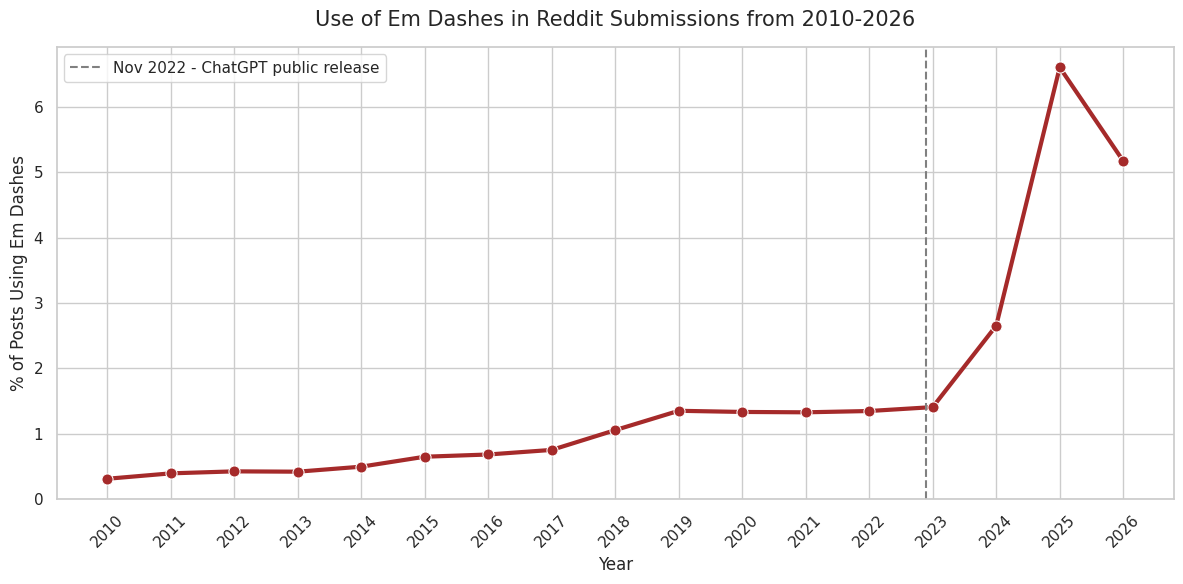

In [ ]:
# third visualization - frequency of em dashes over time (em dashes are characteristic of text written by LLMs)
query = f"""
    SELECT
        CAST(strftime(to_timestamp(created_utc), '%Y') AS INTEGER) AS post_year,
        COUNT(*) AS total_text_posts,
        SUM(
            CASE WHEN
                selftext LIKE '%—%'
            THEN 1 ELSE 0 END
        ) AS advanced_punctuation_count,
        (SUM(
            CASE WHEN
                selftext LIKE '%—%'
            THEN 1 ELSE 0 END
        ) * 100.0 / COUNT(*)) AS pct_with_punctuation
    FROM read_parquet('{random_general_subset}')
    WHERE selftext IS NOT NULL
      AND selftext NOT IN ('[removed]', '[deleted]', '')
    GROUP BY 1
    HAVING COUNT(*) > 1000
    ORDER BY post_year ASC;
"""

em_dashes = db_cnx.sql(query).df()

# creating the line chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=em_dashes,
    x='post_year',
    y='pct_with_punctuation',
    color='brown',
    linewidth=3,
    marker='o',
    markersize=8
)

# also adding a ticked line for when chatgpt was released
plt.axvline(x=2022.9, color='gray', linestyle='--', linewidth=1.5, label='Nov 2022 - ChatGPT public release')

plt.title('Use of Em Dashes in Reddit Submissions from 2010-2026', fontsize=15, pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('% of Posts Using Em Dashes', fontsize=12)
plt.xticks(range(2010, 2027), rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# querying for the top 30 most high volume posters in the political subreddits and the respective subreddits (w accounts still active)
query = f"""
    WITH TopAuthors AS (
        SELECT author, COUNT(*) as total_posts
        FROM read_parquet('{political_subset}')
        WHERE author NOT IN ('[deleted]', '[removed]', 'AutoModerator')
        GROUP BY author
        ORDER BY total_posts DESC
        LIMIT 30
    )
    SELECT
        t.author,
        t.total_posts,
        SUM(CASE WHEN LOWER(r.subreddit) = 'politics' THEN 1 ELSE 0 END) AS politics_posts,
        SUM(CASE WHEN LOWER(r.subreddit) = 'worldnews' THEN 1 ELSE 0 END) AS worldnews_posts,
        SUM(CASE WHEN LOWER(r.subreddit) = 'conservative' THEN 1 ELSE 0 END) AS conservative_posts,
        SUM(CASE WHEN LOWER(r.subreddit) = 'conspiracy' THEN 1 ELSE 0 END) AS conspiracy_posts,
        SUM(CASE WHEN LOWER(r.subreddit) = 'politicaldiscussion' THEN 1 ELSE 0 END) AS politicaldiscussion_posts
    FROM read_parquet('{political_subset}') r
    JOIN TopAuthors t ON r.author = t.author
    GROUP BY t.author, t.total_posts
    ORDER BY t.total_posts DESC;
"""

top_users = db_cnx.sql(query).df()
display(top_users)

,author,total_posts,politics_posts,worldnews_posts,conservative_posts,conspiracy_posts,politicaldiscussion_posts
0,Ask4MD,6474,0.0,306.0,6168.0,0.0,0.0
1,According-Activity87,4532,0.0,0.0,4532.0,0.0,0.0
2,Ok_Savings9315,2324,0.0,2324.0,0.0,0.0,0.0
3,WillyNilly1997,2027,0.0,13.0,2014.0,0.0,0.0
4,M_i_c_K,1941,1.0,0.0,1940.0,0.0,0.0
5,Down-not-out,1652,0.0,0.0,1652.0,0.0,0.0
6,ben_watson_jr,1394,0.0,15.0,1.0,1378.0,0.0
7,triggernaut,1391,0.0,0.0,1391.0,0.0,0.0
8,Murky-Site7468,1367,1367.0,0.0,0.0,0.0,0.0
9,Head_Estate_3944,1153,0.0,0.0,1153.0,0.0,0.0


In [ ]:
# getting total # of posts in political subset, and the total number of unique users who are still active
summary_query = rf"""
    SELECT
        COUNT(*) AS total_posts,
        COUNT(DISTINCT author) AS total_users
    FROM read_parquet('{political_subset}')
    WHERE author IS NOT NULL
      AND author != ''
      AND author NOT IN ('[deleted]', '[removed]', '[auto-moderator]', 'AutoModerator');
"""
total_posts, total_users = db_cnx.sql(summary_query).fetchone()

# total number of posts made by top 30 posters
top_30_query = rf"""
    WITH TopAuthors AS (
        SELECT COUNT(*) as total_posts
        FROM read_parquet('{political_subset}')
        WHERE author NOT IN ('[deleted]', '[removed]', '[auto-moderator]', 'AutoModerator')
        GROUP BY author
        ORDER BY total_posts DESC
        LIMIT 30
    )
    SELECT SUM(total_posts) AS top_30_posts
    FROM TopAuthors;
"""
top_30_posts = db_cnx.sql(top_30_query).fetchone()[0]

top_30_percent = (30 / total_users) * 100
top_30_percent_posts = (top_30_posts / total_posts) * 100

print(f"Total posts in dataset:", total_posts)
print(f"Total users (posters):", total_users)
print(f"Top 30 make up:", top_30_percent, "% of total users")
print(f"Posts by top 30 users:", top_30_posts, "posts total")
print(f"Posts by top 30 users make up:", top_30_percent_posts, "% of all posts)")

Total posts in dataset: 361178
Total users (posters): 83320
Top 30 make up: 0.03600576092174748 % of total users
Posts by top 30 users: 40873 posts total
Posts by top 30 users make up: 11.316580744120627 % of all posts)


In [ ]:
# checking top shared links from top 5 users, ignoring youtube, reddit twitter which were dominating
query = rf"""
    SELECT
        author,
        regexp_extract(LOWER(url), 'https?://(?:www\.)?([^/]+)', 1) AS base_domain,
        COUNT(*) AS total_links_posted,
        SUM(score) AS total_upvotes
    FROM read_parquet('{political_subset}')
    WHERE author IN ('Ask4MD', 'According-Activity87', 'Ok_Savings9315', 'WillyNilly1997', 'M_i_c_K')
      AND url IS NOT NULL AND url != ''
      AND regexp_extract(LOWER(url), 'https?://(?:www\.)?([^/]+)', 1) NOT IN ('', 'reddit.com', 'i.redd.it', 'v.redd.it', 'twitter.com', 'x.com', 'youtube.com')
    GROUP BY 1, 2
    ORDER BY total_links_posted DESC;
"""

top_links = db_cnx.sql(query).df()
display(top_links.head(20))

,author,base_domain,total_links_posted,total_upvotes
0,Ok_Savings9315,aicentral.site,2324,2324.0
1,According-Activity87,nypost.com,1165,297460.0
2,According-Activity87,breitbart.com,822,169625.0
3,According-Activity87,foxnews.com,719,131110.0
4,Ask4MD,redstate.com,705,77266.0
5,WillyNilly1997,foxnews.com,700,73288.0
6,Ask4MD,hotair.com,563,47935.0
7,Ask4MD,nypost.com,478,57987.0
8,Ask4MD,babylonbee.com,439,129713.0
9,According-Activity87,dailycaller.com,384,75497.0


In [ ]:
# detecting users who the exact same link within 1 hour of each other
query = rf"""
    WITH CleanSubmissions AS (
        SELECT
            author,
            url,
            created_utc
        FROM read_parquet('{political_subset}')
        WHERE author NOT IN ('[deleted]', '[removed]', 'AutoModerator')
          AND url IS NOT NULL AND url != ''
          -- Exclude internal Reddit links using standard text matching
          AND LOWER(url) NOT LIKE '%reddit.com%'
          AND LOWER(url) NOT LIKE '%redd.it%'
    )
    SELECT
        u1.author AS user1,
        u2.author AS user2,
        COUNT(*) AS total_overlap_links
    FROM CleanSubmissions u1
    JOIN CleanSubmissions u2
      ON u1.url = u2.url
      AND u1.created_utc BETWEEN u2.created_utc - 3600 AND u2.created_utc + 3600 -- posted within 1 hour
    WHERE u1.author < u2.author -- prevents duplicate reverse pairs
    GROUP BY 1, 2
    ORDER BY total_overlap_links DESC
    LIMIT 30;
"""

duplicate_links = db_cnx.sql(query).df()
display(duplicate_links)

,user1,user2,total_overlap_links
0,RightWingNest,TheClintonHitList,16
1,NewSlinger,mockingbird-,12
2,Ask4MD,M_i_c_K,12
3,Utterly-perplexed,perplexed-redditor,11
4,ElSilbon223,SubjectInevitable650,9
5,nitin_is_me,twicrates,8
6,antihostile,mockingbird-,8
7,Majestic-Fig-524,twicrates,8
8,Old_General_6741,mockingbird-,8
9,Dependent_Cap_456,iwantUineedUohBBohBB,8


In [ ]:
# detecting users who post links to the same domain within 1 hour of each other (i.e., breitbart.com matches, not breitbart.com/article-name)
# this is done bc subreddits often limit/delete duplicate posts, but an entity wanting to promote breitbart could just post diff articles
query = rf"""
    WITH CleanSubmissions AS (
        SELECT
            author,
            REGEXP_EXTRACT(LOWER(url), 'https?://(?:www\.)?([^/]+)', 1) AS base_domain,
            created_utc
        FROM read_parquet('{political_subset}')
        WHERE author NOT IN ('[deleted]', '[removed]', 'AutoModerator')
          AND url IS NOT NULL AND url != ''
          AND REGEXP_EXTRACT(LOWER(url), 'https?://(?:www\.)?([^/]+)', 1) NOT IN ('', 'reddit.com', 'i.redd.it', 'v.redd.it')
    )
    SELECT
        u1.author AS user1,
        u2.author AS user2,
        COUNT(*) AS total_overlap_links
    FROM CleanSubmissions u1
    JOIN CleanSubmissions u2
      ON u1.base_domain = u2.base_domain
      AND u1.created_utc BETWEEN u2.created_utc - 3600 AND u2.created_utc + 3600 -- posted within 1 hour
    WHERE u1.author < u2.author -- prevents duplicate reverse pairs
    GROUP BY 1, 2
    ORDER BY total_overlap_links DESC
    LIMIT 30;
"""

duplicate_base_url = db_cnx.sql(query).df()
display(duplicate_base_url)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,user1,user2,total_overlap_links
0,According-Activity87,Ask4MD,209
1,RightWingNest,TheClintonHitList,208
2,According-Activity87,WillyNilly1997,194
3,Ask4MD,M_i_c_K,178
4,RightWingNest,broc944,172
5,According-Activity87,triggernaut,127
6,According-Activity87,Head_Estate_3944,121
7,Christine2k24,External-Biscotti-94,119
8,Newsweek_CarloV,newsweek,91
9,Down-not-out,WillyNilly1997,86


In [ ]:
# checking if the repeat link posters are also in the top
# getting unique users from above
unique_repeat_link_posters = set(duplicate_base_url['user1']).union(set(duplicate_base_url['user2']))

# repeat link posters that are also in the top 30 authors for the political subreddits
top_repeat_link_users = top_users[top_users['author'].isin(unique_repeat_link_posters)]

# calculating post totals and percents
repeat_link_users_in_top = top_users[top_users['author'].isin(unique_repeat_link_posters)]
repeat_link_total_posts = repeat_link_users_in_top['total_posts'].sum()

repeat_link_total_posts_percent = (repeat_link_total_posts / total_posts) * 100

print("Unique repeat link posters:", len(unique_repeat_link_posters))
print("Number of posts made by unique repeat link posters:", repeat_link_total_posts)
print("Percentage of posts made by unique repeat link posters:", repeat_link_total_posts_percent, "%")
print("Top 30 posters appearing in repeat-link pairs:", len(top_repeat_link_users), "accounts")

Unique repeat link posters: 32
Number of posts made by unique repeat link posters: 27426
Percentage of posts made by unique repeat link posters: 7.593485760483751 %
Top 30 posters appearing in repeat-link pairs: 15 accounts


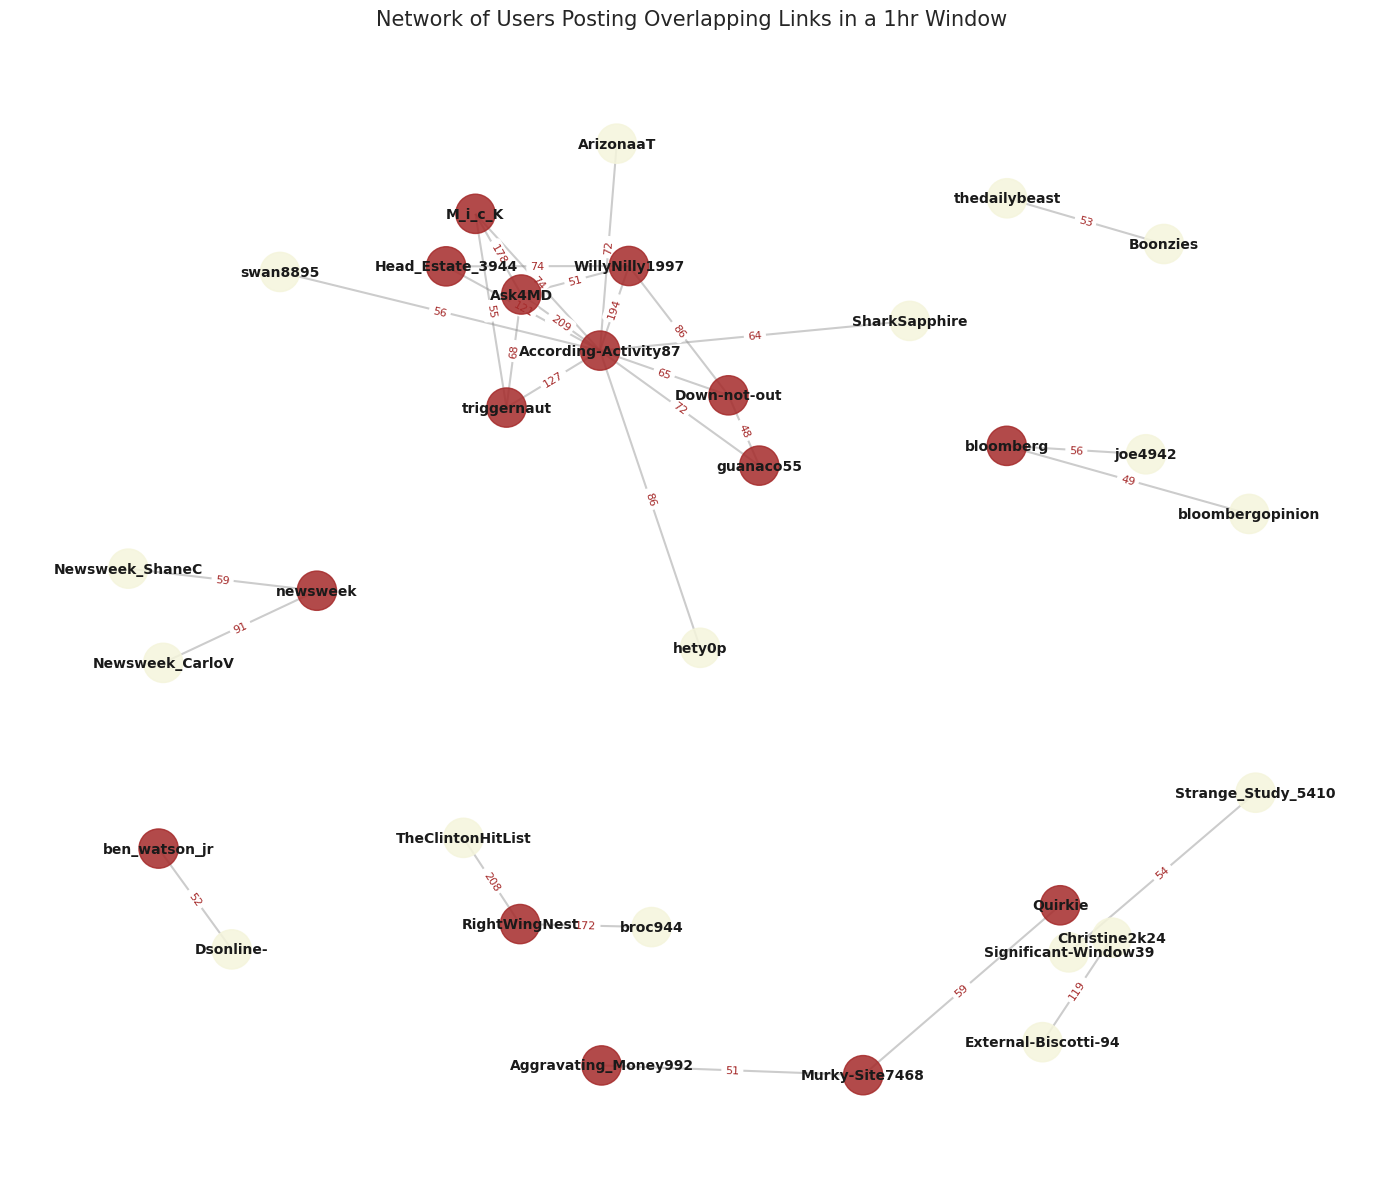

In [ ]:
# fourth visualization - graph of user engagement
user_posts_graph = nx.from_pandas_edgelist(
    duplicate_base_url,
    source='user1',
    target='user2',
    edge_attr='total_overlap_links'
)

plt.figure(figsize=(14, 12))

pos = nx.spring_layout(user_posts_graph, weight='total_overlap_links', k=2.5, seed=42)

# brown nodes are in the top 30 authors, beige aren't
top_authors_set = set(top_users['author'])
node_colors = ['brown' if node in top_authors_set else 'beige' for node in user_posts_graph.nodes()]

# nodes
nx.draw_networkx_nodes(
    user_posts_graph, pos,
    node_size=800,
    node_color=node_colors,
    alpha=0.85
)

# edges
nx.draw_networkx_edges(
    user_posts_graph, pos,
    width=1.5,
    edge_color='gray',
    alpha=0.4
)

# node labels
nx.draw_networkx_labels(
    user_posts_graph, pos,
    font_size=10,
    font_weight='bold',
    font_family='sans-serif'
)

# edge labels w numeric weights
edge_labels = nx.get_edge_attributes(user_posts_graph, 'total_overlap_links')
nx.draw_networkx_edge_labels(
    user_posts_graph, pos,
    edge_labels=edge_labels,
    font_size=8,
    font_color='brown',
)

plt.title('Network of Users Posting Overlapping Links in a 1hr Window', fontsize=15, pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()